# NB1 — Task 1: Baseline CNN & End-to-End Pipeline
____________________________________________________________________________________________________

In this notebook we build the **complete pipeline** that all the other experiments will reuse, and we train a **baseline CNN from scratch** (no pre-trained weights) on EuroSAT.

We will do the following steps in order:

a. Load and normalize the EuroSAT train / validation / test splits (created in NB0)

b. Define a baseline Convolutional Neural Network

c. Define a loss function and an optimizer

d. Train the network, logging **at every epoch**: training loss, validation loss, validation accuracy and per-class validation accuracy

e. Plot the learning curves (loss & accuracy)

f. Test the network on the **unseen test set**: accuracy and normalized confusion matrix

g. Save the checkpoint, load it back and run inference on unseen test mini-batches

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

Using device: cuda:0


**Paths**

The same notebook must run **on Kaggle** (training) and **on our laptop** (live defense). We therefore look for the dataset folder and for `splits.json` in a few possible places instead of hard-coding one path.

In [2]:
ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

# where we save checkpoints and results
OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

# num_workers > 0 can crash on Windows inside notebooks, so we use 0 locally
NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


## a. Loading and normalizing EuroSAT

We reuse the split created in NB0 (**70% train / 15% validation / 15% test**, stratified) and the mean / std of each channel computed on the training images.

``transforms.ToTensor()`` converts the PIL image (values in [0, 255]) to a tensor of shape `[3, 64, 64]` with values in [0, 1].
``transforms.Normalize(mean, std)`` then computes `(x - mean) / std` for each channel, so that each channel is centered on 0 with a std of 1.

In this baseline, there is **no data augmentation** (it will be studied in NB4).

In [3]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]
print("classes:", classes)
print("mean:", MEAN, "| std:", STD)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transform)

trainset = Subset(dataset, splits["train"])
valset = Subset(dataset, splits["val"])
testset = Subset(dataset, splits["test"])
print("train: %d | val: %d | test: %d" % (len(trainset), len(valset), len(testset)))

BATCH_SIZE = 64
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)

classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
mean: [0.34390074014663696, 0.37995412945747375, 0.4075494110584259] | std: [0.20242466032505035, 0.1366828829050064, 0.11540823429822922]
train: 18900 | val: 4050 | test: 4050


**Let us show some of the training images, for fun.**

batch size     : 64
color channels : 3
Image size     : 64x64


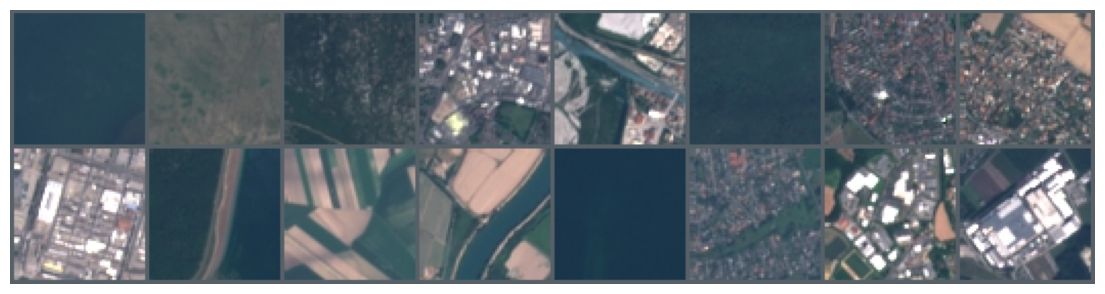

SeaLake | HerbaceousVegetation | HerbaceousVegetation | Industrial | Highway | Forest | Residential | Residential | Industrial | River | AnnualCrop | River | SeaLake | Residential | Industrial | Industrial


In [4]:
def imshow(img):
    # img: normalized tensor [3, H, W] -> unnormalize: x * std + mean
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))  # [3, H, W] -> [H, W, 3] for matplotlib
    plt.axis("off")

data_iter = iter(trainloader)
images, labels = next(data_iter)
print('batch size     :', images.size(0))
print('color channels :', images.size(1))
print('Image size     : ' + str(images.size(2)) + 'x' + str(images.size(3)))

plt.figure(figsize=(14, 4))
imshow(torchvision.utils.make_grid(images[:16], nrow=8))
plt.show()
print(' | '.join('%s' % classes[labels[j]] for j in range(16)))

## b. Define the baseline Convolutional Neural Network

The baseline is a classic **VGG-like** CNN: 3 convolutional blocks followed by 2 fully connected (fc) layers.
Each block is `Conv 3x3 → ReLU → MaxPool 2x2`. The number of feature maps doubles (32 → 64 → 128) while the spatial size is divided by 2 (64 → 32 → 16 → 8).

**Recap:** output size of a Conv2d / MaxPool2d layer with input size `h_in`, kernel `k`, padding `p`, stride `s`:

$$h_{out} = \left\lfloor \frac{h_{in} + 2p - k}{s} \right\rfloor + 1$$

With `k=3, p=1, s=1`: $h_{out} = (h_{in} + 2 - 3)/1 + 1 = h_{in}$ → the convolution keeps the size ("same" padding).
With MaxPool `k=2, s=2`: $h_{out} = (h_{in} - 2)/2 + 1 = h_{in}/2$.

On purpose, this baseline has **no Batch Normalization, no dropout and no data augmentation**: these are the improvements studied in Task 2.

In [5]:
class Net(nn.Module):
    def __init__(self, num_classes=10):
        super(Net, self).__init__()
        # block 1 | input 3x64x64 | conv output 32x64x64 | h_out = (64 + 2*1 - 3)/1 + 1 = 64
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        # block 2 | input 32x32x32 | conv output 64x32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        # block 3 | input 64x16x16 | conv output 128x16x16
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # kernel=2x2 | stride=2: the size of the feature maps is divided by 2 | h_out = (64 - 2)/2 + 1 = 32
        self.pool = nn.MaxPool2d(2, 2)

        # after 3 pools: 128 feature maps of 8x8 -> flatten -> 128*8*8 = 8192 features
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)  # 10 outputs = 10 classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 32, 32]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 16, 16]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 8, 8]
        x = torch.flatten(x, 1)               # [B, 8192] flatten all dimensions except batch
        x = F.relu(self.fc1(x))               # [B, 256]
        x = self.fc2(x)                       # [B, 10] scores (logits) of the 10 classes
        return x


net = Net(num_classes).to(device)
print(net)

# total number of learnable parameters (weights + biases)
n_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print("Number of parameters: %d (%.2f M)" % (n_params, n_params / 1e6))

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
Number of parameters: 2193226 (2.19 M)


**Check the shapes** by sending one batch through the network:

In [6]:
x = images[:4].to(device)
print("input :", x.shape)
print("output:", net(x).shape)

input : torch.Size([4, 3, 64, 64])
output: torch.Size([4, 10])


## c. Define a Loss function and optimizer

- **Loss:** ``nn.CrossEntropyLoss`` = Softmax + negative log-likelihood. It takes the raw scores (logits) of the network and the integer labels.
- **Optimizer:** SGD with momentum 0.9 and learning rate 0.01, as in the labs. (Other optimizers and learning rates are compared in NB3.)

In [7]:
criterion = nn.CrossEntropyLoss()  # default returns the mean of losses over the batch
LR = 0.01
optimizer = optim.SGD(net.parameters(), lr=LR, momentum=0.9)

## d. Train the network

We write two helper functions, used in all the notebooks of the project:

- `train_one_epoch`: one pass over the training set (forward → loss → backward → optimizer step). Returns the mean training loss and accuracy.
- `evaluate`: one pass over a validation / test set **without** computing gradients. Returns the mean loss, the accuracy, the **per-class accuracy**, and all predictions (for the confusion matrix).

**Why `net.train()` and `net.eval()`?** Some layers behave differently during training and testing (Dropout, BatchNorm). Our baseline has none of them, but we keep the good habit because the next models will.

In [8]:
def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, data in enumerate(loader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # statistics (loss.item() is the mean over the batch -> multiply by the batch size)
        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():  # torch.no_grad for TESTING: no gradients -> faster and less memory
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = 100.0 * (all_preds == all_labels).mean()
    # per-class accuracy: among the images of class c, how many are predicted as c
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels

**Training loop**

At every epoch we record everything in the dictionary `history`. We also keep a copy of the weights of the epoch with the **best validation accuracy** (this is the checkpoint we will use on the test set).

In [9]:
n_epochs = 30
RUN_NAME = "NB1_baseline_sgd_lr%g_bs%d_%dep" % (LR, BATCH_SIZE, n_epochs)
CKPT_PATH = os.path.join(CKPT_DIR, RUN_NAME + ".pth")

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_per_class_acc": [], "epoch_time": []}
best_val_acc = 0.0

for epoch in range(n_epochs):  # loop over the dataset multiple times
    start = time.time()
    train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer)
    val_loss, val_acc, val_per_class_acc, _, _ = evaluate(net, valloader, criterion)
    epoch_time = time.time() - start

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_per_class_acc"].append(val_per_class_acc)
    history["epoch_time"].append(epoch_time)

    # save the best model (on the validation set)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(net.state_dict(), CKPT_PATH)

    print('[epoch %2d] train loss: %.3f | train acc: %.2f %% | val loss: %.3f | val acc: %.2f %% | %.1f s' %
          (epoch + 1, train_loss, train_acc, val_loss, val_acc, epoch_time))

print('Finished Training | best val acc: %.2f %%' % best_val_acc)

with open(os.path.join(RES_DIR, RUN_NAME + "_history.json"), "w") as f:
    json.dump(history, f)

[epoch  1] train loss: 1.309 | train acc: 50.84 % | val loss: 0.956 | val acc: 63.31 % | 26.7 s
[epoch  2] train loss: 0.739 | train acc: 73.19 % | val loss: 0.727 | val acc: 72.72 % | 12.0 s
[epoch  3] train loss: 0.566 | train acc: 79.79 % | val loss: 0.604 | val acc: 78.22 % | 11.3 s
[epoch  4] train loss: 0.451 | train acc: 84.12 % | val loss: 0.572 | val acc: 80.20 % | 14.4 s
[epoch  5] train loss: 0.359 | train acc: 87.52 % | val loss: 0.395 | val acc: 85.95 % | 12.9 s
[epoch  6] train loss: 0.292 | train acc: 89.84 % | val loss: 0.391 | val acc: 86.94 % | 12.6 s
[epoch  7] train loss: 0.243 | train acc: 91.41 % | val loss: 0.639 | val acc: 82.79 % | 9.7 s
[epoch  8] train loss: 0.182 | train acc: 93.62 % | val loss: 0.401 | val acc: 87.68 % | 12.1 s
[epoch  9] train loss: 0.125 | train acc: 95.77 % | val loss: 0.515 | val acc: 84.64 % | 12.6 s
[epoch 10] train loss: 0.100 | train acc: 96.61 % | val loss: 0.506 | val acc: 87.11 % | 12.8 s
[epoch 11] train loss: 0.065 | train acc:

**Per-class validation accuracy, at every epoch**

In [10]:
print('%22s' % 'epoch', ' '.join('%5d' % (e + 1) for e in range(0, n_epochs, 5)))
for c in range(num_classes):
    print('%22s' % classes[c], ' '.join('%5.1f' % history["val_per_class_acc"][e][c] for e in range(0, n_epochs, 5)))

                 epoch     1     6    11    16    21    26
            AnnualCrop  54.0  89.6  92.2  91.1  86.4  88.0
                Forest  95.1  94.7  96.0  96.4  98.0  96.7
  HerbaceousVegetation  39.3  76.2  85.8  82.7  76.9  80.9
               Highway  37.9  68.0  80.5  79.2  84.5  81.1
            Industrial  76.5  88.8  87.7  94.7  93.1  93.1
               Pasture  59.0  88.7  86.7  94.3  94.3  91.3
         PermanentCrop  81.1  81.9  71.5  84.0  82.1  83.7
           Residential  94.7  98.2  99.3  95.1  96.9  96.7
                 River  41.3  81.3  72.0  74.1  80.8  80.0
               SeaLake  50.0  98.0  98.7  96.7  96.7  97.3


## e. Learning curves

We plot the loss and the accuracy of the training and validation sets on the same figure.

- If the **training loss keeps decreasing while the validation loss increases**, the network is **overfitting**: it memorizes the training images instead of learning features that generalize.
- The **generalization gap** = train accuracy − validation accuracy.

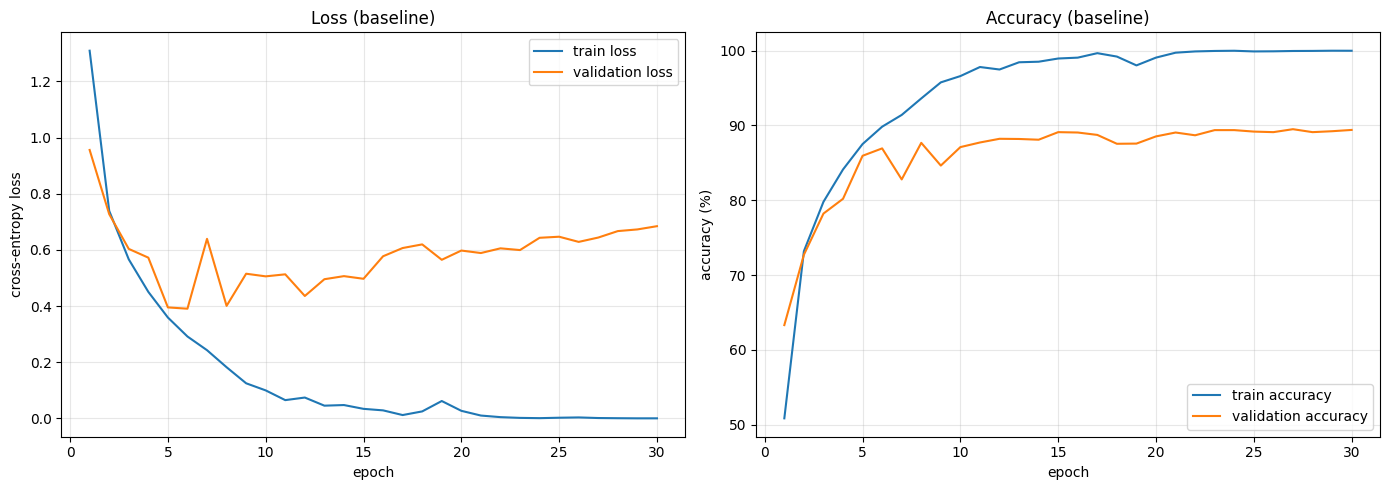

In [11]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["val_loss"], label="validation loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss"); ax1.set_title("Loss " + title)
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history["train_acc"], label="train accuracy")
    ax2.plot(epochs, history["val_acc"], label="validation accuracy")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)"); ax2.set_title("Accuracy " + title)
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(history, "(baseline)")

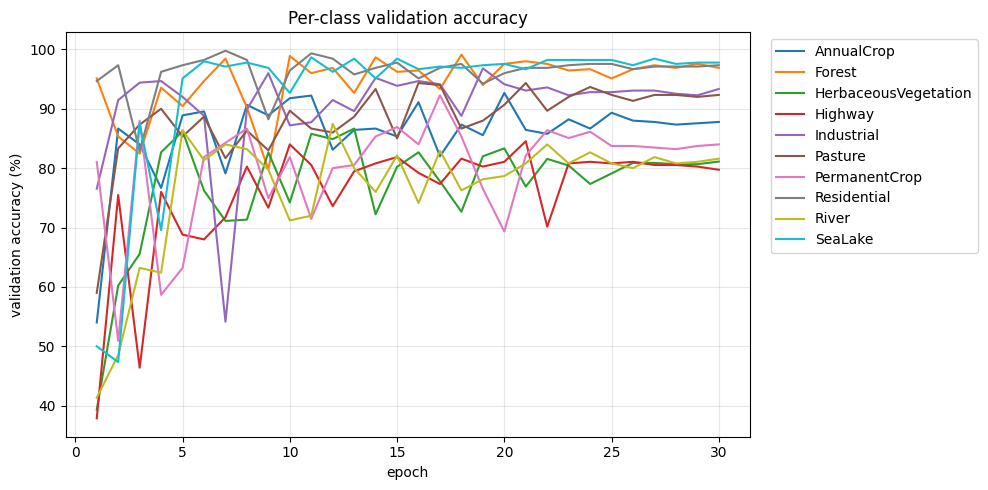

In [12]:
# per-class validation accuracy across epochs
per_class = np.array(history["val_per_class_acc"])  # shape [n_epochs, num_classes]
plt.figure(figsize=(10, 5))
for c in range(num_classes):
    plt.plot(range(1, n_epochs + 1), per_class[:, c], label=classes[c])
plt.xlabel("epoch"); plt.ylabel("validation accuracy (%)"); plt.title("Per-class validation accuracy")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## f. Test the network on the unseen test data

We load back the checkpoint with the **best validation accuracy**, and evaluate it **once** on the test set (4050 images never used during training or model selection).

In [13]:
best_net = Net(num_classes).to(device)
best_net.load_state_dict(torch.load(CKPT_PATH, map_location=device))

test_loss, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(best_net, testloader, criterion)
print('Accuracy of the network on the %d test images: %.2f %%' % (len(testset), test_acc))
print()
for c in range(num_classes):
    print('Accuracy of %22s : %.1f %%' % (classes[c], test_per_class_acc[c]))

Accuracy of the network on the 4050 test images: 90.15 %

Accuracy of             AnnualCrop : 90.7 %
Accuracy of                 Forest : 97.1 %
Accuracy of   HerbaceousVegetation : 86.4 %
Accuracy of                Highway : 76.8 %
Accuracy of             Industrial : 93.9 %
Accuracy of                Pasture : 92.3 %
Accuracy of          PermanentCrop : 80.5 %
Accuracy of            Residential : 96.0 %
Accuracy of                  River : 86.4 %
Accuracy of                SeaLake : 98.2 %


**Normalized confusion matrix**

Row `i`, column `j` = fraction of the images of true class `i` that were predicted as class `j`. Each row sums to 1. The diagonal is the per-class accuracy (recall); everything outside the diagonal is a confusion between two classes.

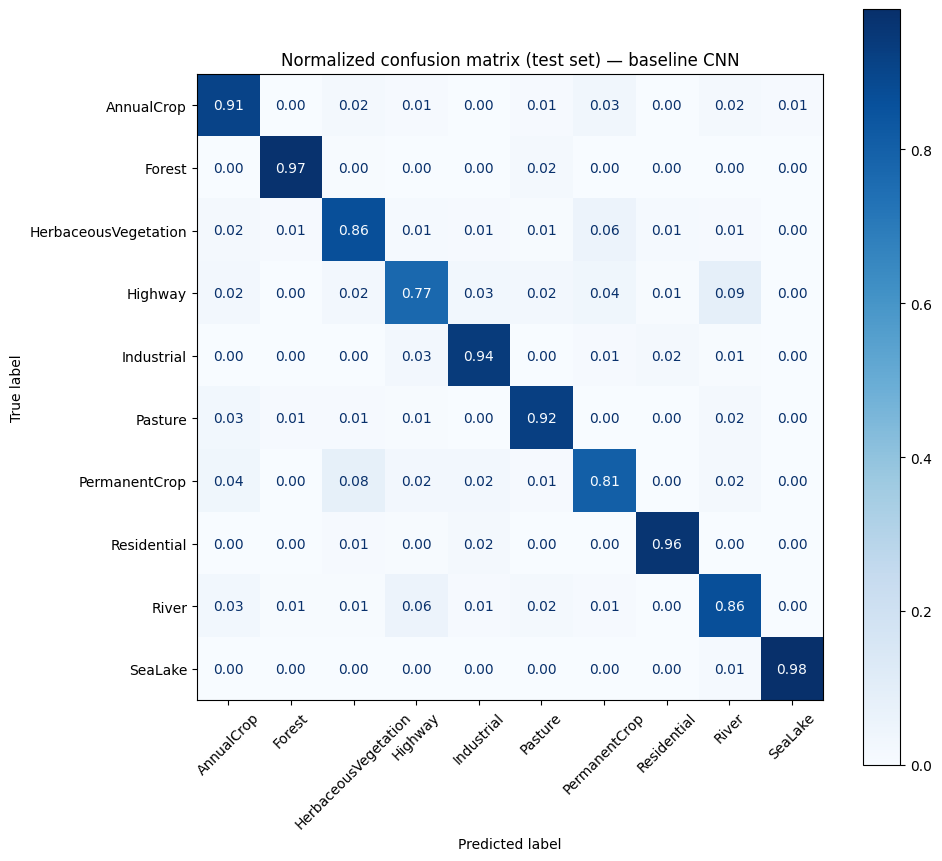

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized confusion matrix (test set) — baseline CNN")
plt.tight_layout()
plt.show()

In [15]:
# most confused pairs of classes (largest off-diagonal values)
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
pairs = np.dstack(np.unravel_index(np.argsort(-off_diag.ravel()), off_diag.shape))[0][:5]
print("Most confused pairs (true -> predicted):")
for i, j in pairs:
    print('  %22s -> %-22s : %.1f %% of the %s images' % (classes[i], classes[j], 100 * off_diag[i, j], classes[i]))

print()
print(classification_report(test_labels, test_preds, target_names=classes, digits=3))

Most confused pairs (true -> predicted):
                 Highway -> River                  : 8.8 % of the Highway images
           PermanentCrop -> HerbaceousVegetation   : 8.3 % of the PermanentCrop images
                   River -> Highway                : 5.6 % of the River images
    HerbaceousVegetation -> PermanentCrop          : 5.6 % of the HerbaceousVegetation images
                 Highway -> PermanentCrop          : 3.7 % of the Highway images

                      precision    recall  f1-score   support

          AnnualCrop      0.891     0.907     0.899       450
              Forest      0.971     0.971     0.971       450
HerbaceousVegetation      0.864     0.864     0.864       450
             Highway      0.840     0.768     0.802       375
          Industrial      0.905     0.939     0.921       375
             Pasture      0.882     0.923     0.902       300
       PermanentCrop      0.830     0.805     0.817       375
         Residential      0.969     0.9

**Some misclassified test images**

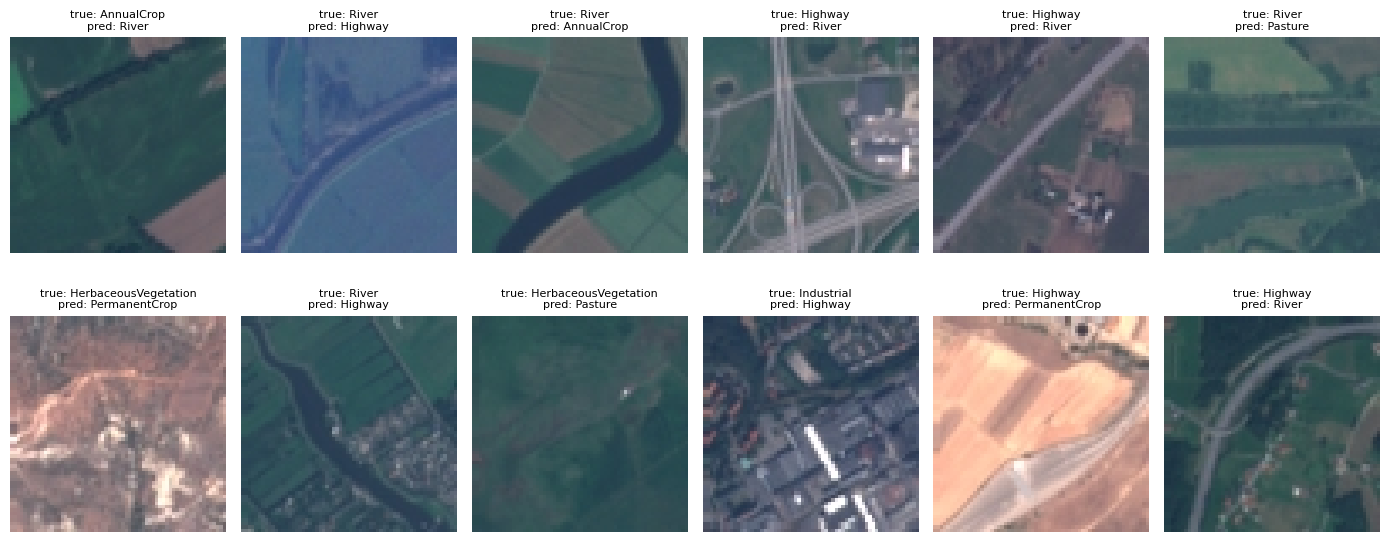

In [16]:
wrong = np.where(test_preds != test_labels)[0][:12]
plt.figure(figsize=(14, 6))
for k, i in enumerate(wrong):
    img, _ = testset[i]
    plt.subplot(2, 6, k + 1)
    imshow(img)
    plt.title("true: %s\npred: %s" % (classes[test_labels[i]], classes[test_preds[i]]), fontsize=8)
plt.tight_layout()
plt.show()

## g. Load the saved checkpoint and test it on unseen mini-batches

This is what we will do during the defense: create a **new** network, load the saved weights (`.pth`) and run inference on test mini-batches.

The `.pth` file only contains the `state_dict` (a Python dictionary mapping each layer to its parameter tensors), so we first need to create the same architecture (`Net`) and then load the weights into it.

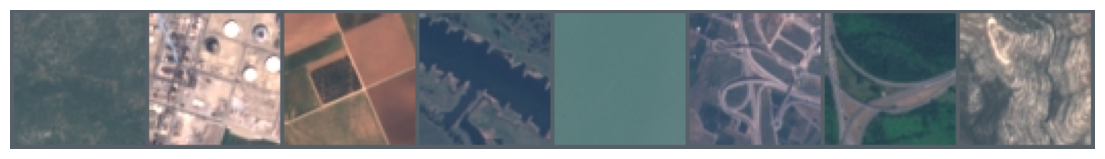

GroundTruth:  HerbaceousVegetation | Industrial | AnnualCrop | River | SeaLake | Highway | Highway | HerbaceousVegetation
Predicted  :  HerbaceousVegetation (1.00) | Industrial (1.00) | PermanentCrop (1.00) | River (1.00) | SeaLake (1.00) | Industrial (1.00) | Highway (1.00) | PermanentCrop (0.98)


In [17]:
PATH = CKPT_PATH
trainednet = Net(num_classes)
trainednet.load_state_dict(torch.load(PATH, map_location="cpu"))  # map_location: works even without a GPU
trainednet.eval()

# a random mini-batch of the TEST set
demo_loader = DataLoader(testset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))

with torch.no_grad():
    outputs = trainednet(images)              # [8, 10] scores
    probs = F.softmax(outputs, dim=1)         # scores -> probabilities
    conf, predicted = torch.max(probs, 1)     # highest probability and its class index

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))

In [18]:
# accuracy of the reloaded checkpoint on the whole test set (should match section f)
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = trainednet(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print('Reloaded checkpoint — accuracy on the %d test images: %.2f %%' % (total, 100 * correct / total))

Reloaded checkpoint — accuracy on the 4050 test images: 90.15 %


## Summary

We save the main numbers of the baseline; they will be the first line of the final comparison table (NB7).

In [19]:
# inference latency: time to classify one image (batch of 1) on the current device
net_lat = best_net.eval()
x = torch.randn(1, 3, 64, 64).to(device)
with torch.no_grad():
    for _ in range(10):  # warm-up
        net_lat(x)
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()
    for _ in range(100):
        net_lat(x)
    if device.type == "cuda": torch.cuda.synchronize()
latency_ms = (time.time() - start) / 100 * 1000

best_epoch = int(np.argmax(history["val_acc"]))
summary = {
    "run": RUN_NAME,
    "params": n_params,
    "latency_ms": latency_ms,
    "best_val_acc": best_val_acc,
    "best_epoch": best_epoch + 1,
    "gen_gap": history["train_acc"][best_epoch] - history["val_acc"][best_epoch],
    "test_acc": test_acc,
    "train_time_s": sum(history["epoch_time"]),
}
with open(os.path.join(RES_DIR, RUN_NAME + "_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
for k, v in summary.items():
    print('%14s : %s' % (k, v))

           run : NB1_baseline_sgd_lr0.01_bs64_30ep
        params : 2193226
    latency_ms : 0.3439974784851074
  best_val_acc : 89.50617283950618
    best_epoch : 27
       gen_gap : 10.456790123456784
      test_acc : 90.14814814814814
  train_time_s : 346.3304328918457
